In [8]:
# AIS Data Exploratory Analysis
# Analysis of March 2025 AIS Maritime Data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import folium
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Import our custom utilities
import sys
import os

# Add parent directory of 'utils' to sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "utils")))
from ais_visualization_utils import AISVisualizer, create_summary_report


print("📊 AIS Data Exploration Notebook")
print("=" * 50)
print("This notebook provides comprehensive exploratory analysis of AIS maritime data")
print("Data period: March 2025 (Full month)")
print("=" * 50)


📊 AIS Data Exploration Notebook
This notebook provides comprehensive exploratory analysis of AIS maritime data
Data period: March 2025 (Full month)


In [2]:
## 1. Data Loading and Initial Exploration

# Define data path
data_path = Path('../data/march_2025_files')
parquet_files = list(data_path.glob('*.parquet'))

print(f"📁 Found {len(parquet_files)} parquet files")
print(f"Date range: {parquet_files[0].stem} to {parquet_files[-1].stem}")

# Load a sample file to understand the structure
sample_file = parquet_files[0]  # First file
print(f"\n🔍 Loading sample file: {sample_file.name}")

try:
    sample_df = pd.read_parquet(sample_file)
    print(f"✅ Successfully loaded sample data")
    print(f"Sample file shape: {sample_df.shape}")
    
    # Display basic information
    print("\n📋 Data Structure:")
    print("-" * 30)
    print(f"Columns ({len(sample_df.columns)}): {list(sample_df.columns)}")
    print(f"\nData types:")
    for col, dtype in sample_df.dtypes.items():
        print(f"  {col}: {dtype}")
    
    print(f"\nFirst few records:")
    display(sample_df.head())
    
    print(f"\nBasic statistics:")
    display(sample_df.describe())
    
except Exception as e:
    print(f"❌ Error loading sample file: {e}")
    print("Please check the file path and format")


📁 Found 31 parquet files
Date range: ais-2025-03-01 to ais-2025-03-31

🔍 Loading sample file: ais-2025-03-01.parquet
✅ Successfully loaded sample data
Sample file shape: (7827106, 17)

📋 Data Structure:
------------------------------
Columns (17): ['MMSI', 'BaseDateTime', 'LAT', 'LON', 'SOG', 'COG', 'Heading', 'VesselName', 'IMO', 'CallSign', 'VesselType', 'Status', 'Length', 'Width', 'Draft', 'Cargo', 'TransceiverClass']

Data types:
  MMSI: uint64
  BaseDateTime: object
  LAT: float64
  LON: float64
  SOG: float64
  COG: float64
  Heading: float64
  VesselName: object
  IMO: object
  CallSign: object
  VesselType: object
  Status: object
  Length: float64
  Width: float64
  Draft: float64
  Cargo: float64
  TransceiverClass: object

First few records:


,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading,VesselName,IMO,CallSign,VesselType,Status,Length,Width,Draft,Cargo,TransceiverClass
0,367731330,2025-03-01 00:00:00,-90.01258,29.79715,0.1,160.7,18.0,AMAZING GRACE,None,WDI7701,31,12,23.0,8.0,9.0,99.0,A
1,368145380,2025-03-01 00:00:00,-95.07382,29.78248,0.1,305.2,218.0,DRUM BAY,None,WDL5885,57,12,132.0,34.0,3.4,57.0,A
2,369494415,2025-03-01 00:00:03,-85.75557,30.17031,0.0,65.6,3.0,CG49415,None,None,51,0,15.0,5.0,1.0,51.0,A
3,367055690,2025-03-01 00:00:04,-157.96063,21.35289,0.0,8.5,NaN,AMERICAN EMERALD,IMO8842296,WDC6392,52,0,22.0,9.0,2.6,52.0,A
4,367177840,2025-03-01 00:00:06,-75.12802,39.90357,0.2,199.7,357.0,BART TURECAMO,IMO7338808,WBR4464,52,0,30.0,8.0,3.9,52.0,A



Basic statistics:


,MMSI,LAT,LON,SOG,COG,Heading,Length,Width,Draft,Cargo
count,7.827106e+06,7.827106e+06,7.827106e+06,7.810117e+06,6.485858e+06,3.870907e+06,7.667388e+06,7.562733e+06,4.308275e+06,5.187278e+06
mean,3.684799e+08,-9.451526e+01,3.399557e+01,2.037149e+00,1.836389e+02,1.832297e+02,6.358748e+01,1.285080e+01,4.627720e+00,5.513767e+01
std,6.126992e+07,2.056849e+01,7.849890e+00,4.337030e+00,1.055140e+02,1.060933e+02,8.079872e+01,1.071670e+01,3.048790e+00,1.800445e+01
min,1.000118e+08,-1.680075e+02,-1.642841e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e-01,1.000000e+00
25%,3.548860e+08,-1.172349e+02,2.912350e+01,0.000000e+00,9.160000e+01,9.000000e+01,1.700000e+01,6.000000e+00,2.700000e+00,4.000000e+01
50%,3.674799e+08,-9.040132e+01,3.036833e+01,0.000000e+00,1.935000e+02,1.840000e+02,2.600000e+01,9.000000e+00,3.100000e+00,5.200000e+01
75%,3.681341e+08,-8.014139e+01,3.984303e+01,9.000000e-01,2.715000e+02,2.740000e+02,6.800000e+01,1.600000e+01,6.000000e+00,6.900000e+01
max,1.000000e+09,1.455548e+02,8.589074e+01,9.530000e+01,3.599000e+02,3.590000e+02,4.890000e+02,6.100000e+01,2.400000e+01,1.900000e+02


In [3]:
## 2. Data Quality Assessment

print("🔍 Data Quality Analysis")
print("=" * 40)

# Check for missing values
print("Missing values per column:")
missing_values = sample_df.isnull().sum()
missing_pct = (missing_values / len(sample_df)) * 100

for col in sample_df.columns:
    if missing_values[col] > 0:
        print(f"  {col}: {missing_values[col]:,} ({missing_pct[col]:.2f}%)")
    else:
        print(f"  {col}: No missing values")

# Check for duplicates
duplicates = sample_df.duplicated().sum()
print(f"\nDuplicate records: {duplicates:,} ({duplicates/len(sample_df)*100:.2f}%)")

# Check coordinate validity (if LAT/LON columns exist)
coord_cols = [col for col in ['LAT', 'LOT', 'LATITUDE', 'LONGITUDE'] if col in sample_df.columns]
if len(coord_cols) >= 2:
    lat_col, lon_col = coord_cols[0], coord_cols[1]
    print(f"\n🌍 Geographic Coordinate Analysis:")
    print(f"Latitude column: {lat_col}")
    print(f"Longitude column: {lon_col}")
    
    # Valid coordinate ranges: LAT [-90, 90], LON [-180, 180]
    valid_lat = (sample_df[lat_col] >= -90) & (sample_df[lat_col] <= 90)
    valid_lon = (sample_df[lon_col] >= -180) & (sample_df[lon_col] <= 180)
    valid_coords = valid_lat & valid_lon & sample_df[lat_col].notna() & sample_df[lon_col].notna()
    
    print(f"Valid coordinates: {valid_coords.sum():,} ({valid_coords.sum()/len(sample_df)*100:.2f}%)")
    print(f"Invalid/missing coordinates: {(~valid_coords).sum():,}")
    
    # Geographic bounds
    valid_data = sample_df[valid_coords]
    if len(valid_data) > 0:
        print(f"\nGeographic bounds:")
        print(f"  Latitude: [{valid_data[lat_col].min():.4f}, {valid_data[lat_col].max():.4f}]")
        print(f"  Longitude: [{valid_data[lon_col].min():.4f}, {valid_data[lon_col].max():.4f}]")
else:
    print("\n⚠️ No standard coordinate columns found")

# Check for common AIS columns
ais_columns = ['MMSI', 'SOG', 'COG', 'BaseDateTime', 'VesselType', 'CallSign']
print(f"\n🚢 AIS Standard Columns Present:")
for col in ais_columns:
    if col in sample_df.columns:
        print(f"  ✅ {col}")
    else:
        print(f"  ❌ {col} (not found)")


🔍 Data Quality Analysis
Missing values per column:
  MMSI: No missing values
  BaseDateTime: No missing values
  LAT: No missing values
  LON: No missing values
  SOG: 16,989 (0.22%)
  COG: 1,341,248 (17.14%)
  Heading: 3,956,199 (50.54%)
  VesselName: 9,968 (0.13%)
  IMO: 4,663,489 (59.58%)
  CallSign: 969,752 (12.39%)
  VesselType: 61,490 (0.79%)
  Status: 2,807,131 (35.86%)
  Length: 159,718 (2.04%)
  Width: 264,373 (3.38%)
  Draft: 3,518,831 (44.96%)
  Cargo: 2,639,828 (33.73%)
  TransceiverClass: No missing values

Duplicate records: 1,438 (0.02%)

⚠️ No standard coordinate columns found

🚢 AIS Standard Columns Present:
  ✅ MMSI
  ✅ SOG
  ✅ COG
  ✅ BaseDateTime
  ✅ VesselType
  ✅ CallSign


In [4]:
## 3. Load Multiple Files for Comprehensive Analysis

print("📂 Loading Multiple Files for Comprehensive Analysis")
print("=" * 50)

# Option 1: Load all files (memory intensive)
# Option 2: Load a sample from multiple files (recommended for exploration)
# Let's start with a few files to get a good sample

# Load first few days for comprehensive analysis
sample_files = parquet_files[:7]  # First week
print(f"Loading {len(sample_files)} files for analysis...")

dfs = []
for file in sample_files:
    try:
        df = pd.read_parquet(file)
        df['source_file'] = file.stem  # Add source file information
        dfs.append(df)
        print(f"  ✅ Loaded {file.name}: {df.shape[0]:,} records")
    except Exception as e:
        print(f"  ❌ Error loading {file.name}: {e}")

if dfs:
    # Combine all dataframes
    combined_df = pd.concat(dfs, ignore_index=True)
    print(f"\n📊 Combined Dataset:")
    print(f"  Total records: {len(combined_df):,}")
    print(f"  Total columns: {len(combined_df.columns)}")
    print(f"  Memory usage: {combined_df.memory_usage(deep=True).sum() / 1024 / 1024:.2f} MB")
    print(f"  Date range: {combined_df['source_file'].min()} to {combined_df['source_file'].max()}")
    
    # Store for later analysis
    analysis_df = combined_df.copy()
else:
    print("❌ No files could be loaded")


📂 Loading Multiple Files for Comprehensive Analysis
Loading 7 files for analysis...
  ✅ Loaded ais-2025-03-01.parquet: 7,827,106 records
  ✅ Loaded ais-2025-03-02.parquet: 7,672,088 records
  ✅ Loaded ais-2025-03-03.parquet: 7,581,995 records
  ✅ Loaded ais-2025-03-04.parquet: 7,789,207 records
  ✅ Loaded ais-2025-03-05.parquet: 7,829,436 records
  ✅ Loaded ais-2025-03-06.parquet: 7,343,257 records
  ✅ Loaded ais-2025-03-07.parquet: 7,867,108 records

📊 Combined Dataset:
  Total records: 53,910,197
  Total columns: 18
  Memory usage: 25826.78 MB
  Date range: ais-2025-03-01 to ais-2025-03-07


⏰ Temporal Pattern Analysis
Using timestamp column: BaseDateTime
Converting timestamp to datetime...

📅 Daily Record Distribution:
  2025-03-01: 7,827,106 records
  2025-03-02: 7,672,088 records
  2025-03-03: 7,581,995 records
  2025-03-04: 7,789,207 records
  2025-03-05: 7,829,436 records
  2025-03-06: 7,343,257 records
  2025-03-07: 7,867,108 records

🕐 Hourly Pattern Analysis:
Hour | Records
---------------
 0:00 | 2,156,766
 3:00 | 2,159,976
 6:00 | 2,176,327
 9:00 | 2,161,161
12:00 | 2,244,104
15:00 | 2,342,591
18:00 | 2,410,231
21:00 | 2,373,236


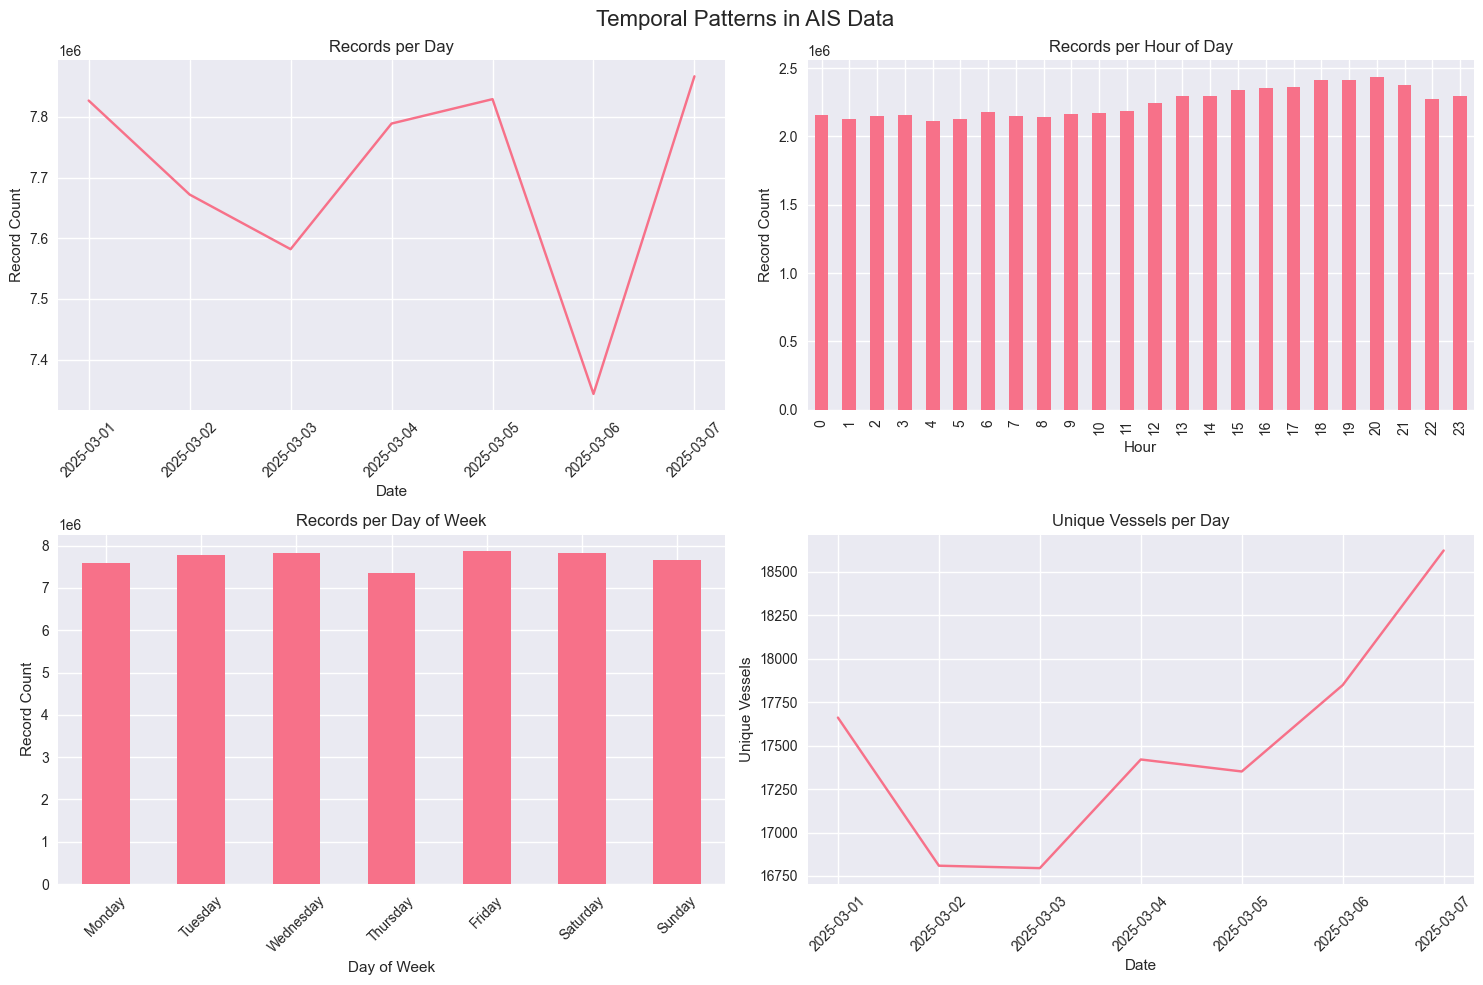

In [9]:
## 4. Temporal Analysis

print("⏰ Temporal Pattern Analysis")
print("=" * 40)

# Initialize visualizer
visualizer = AISVisualizer()

# Find timestamp column
timestamp_cols = [col for col in analysis_df.columns if any(word in col.upper() for word in ['TIME', 'DATE', 'TIMESTAMP'])]
if timestamp_cols:
    timestamp_col = timestamp_cols[0]
    print(f"Using timestamp column: {timestamp_col}")
    
    # Convert to datetime if not already
    if not pd.api.types.is_datetime64_any_dtype(analysis_df[timestamp_col]):
        print("Converting timestamp to datetime...")
        analysis_df[timestamp_col] = pd.to_datetime(analysis_df[timestamp_col])
    
    # Daily record counts
    print("\n📅 Daily Record Distribution:")
    daily_counts = analysis_df[timestamp_col].dt.date.value_counts().sort_index()
    for date, count in daily_counts.items():
        print(f"  {date}: {count:,} records")
    
    # Hourly patterns
    print("\n🕐 Hourly Pattern Analysis:")
    hourly_counts = analysis_df[timestamp_col].dt.hour.value_counts().sort_index()
    print("Hour | Records")
    print("-" * 15)
    for hour in range(0, 24, 3):  # Show every 3 hours
        count = hourly_counts.get(hour, 0)
        print(f"{hour:2d}:00 | {count:,}")
    
    # Create temporal visualization
    try:
        fig_temporal = visualizer.plot_temporal_patterns(analysis_df, timestamp_col)
        plt.show()
    except Exception as e:
        print(f"⚠️ Error creating temporal visualization: {e}")
        
else:
    print("⚠️ No timestamp column found for temporal analysis")


🚢 Vessel Analysis
Using vessel column: MMSI

📊 Vessel Statistics:
  Total unique vessels: 26,121
  Total records: 53,910,197
  Average records per vessel: 2063.9

🏆 Top 10 Most Active Vessels:
   1. Vessel 367653630: 9,320 records (0.02%)
   2. Vessel 367531220: 9,237 records (0.02%)
   3. Vessel 338199855: 9,185 records (0.02%)
   4. Vessel 369970411: 9,123 records (0.02%)
   5. Vessel 368257130: 9,110 records (0.02%)
   6. Vessel 367327250: 9,086 records (0.02%)
   7. Vessel 367331730: 9,077 records (0.02%)
   8. Vessel 368179250: 9,052 records (0.02%)
   9. Vessel 367740820: 9,041 records (0.02%)
  10. Vessel 367156340: 9,031 records (0.02%)

📈 Vessel Activity Distribution:
  Vessels with 1 record: 793
  Vessels with 2-10 records: 1,541
  Vessels with 11-100 records: 3,320
  Vessels with 100+ records: 20,467


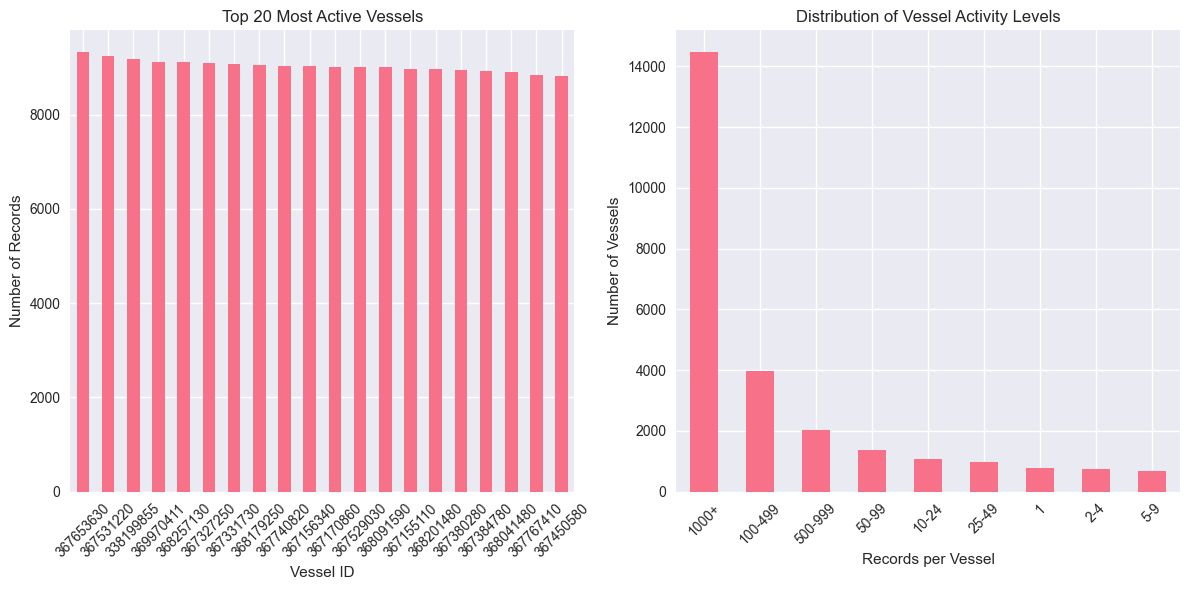

In [10]:
## 5. Vessel Analysis

print("🚢 Vessel Analysis")
print("=" * 30)

# Find vessel identifier column (usually MMSI)
vessel_cols = [col for col in analysis_df.columns if any(word in col.upper() for word in ['MMSI', 'VESSEL', 'SHIP'])]
if vessel_cols:
    vessel_col = vessel_cols[0]
    print(f"Using vessel column: {vessel_col}")
    
    # Basic vessel statistics
    total_vessels = analysis_df[vessel_col].nunique()
    total_records = len(analysis_df)
    avg_records_per_vessel = total_records / total_vessels
    
    print(f"\n📊 Vessel Statistics:")
    print(f"  Total unique vessels: {total_vessels:,}")
    print(f"  Total records: {total_records:,}")
    print(f"  Average records per vessel: {avg_records_per_vessel:.1f}")
    
    # Most active vessels
    print(f"\n🏆 Top 10 Most Active Vessels:")
    top_vessels = analysis_df[vessel_col].value_counts().head(10)
    for i, (vessel, count) in enumerate(top_vessels.items(), 1):
        pct = count / total_records * 100
        print(f"  {i:2d}. Vessel {vessel}: {count:,} records ({pct:.2f}%)")
    
    # Vessel activity distribution
    vessel_activity = analysis_df[vessel_col].value_counts()
    print(f"\n📈 Vessel Activity Distribution:")
    print(f"  Vessels with 1 record: {(vessel_activity == 1).sum():,}")
    print(f"  Vessels with 2-10 records: {((vessel_activity >= 2) & (vessel_activity <= 10)).sum():,}")
    print(f"  Vessels with 11-100 records: {((vessel_activity >= 11) & (vessel_activity <= 100)).sum():,}")
    print(f"  Vessels with 100+ records: {(vessel_activity > 100).sum():,}")
    
    # Visualize vessel activity
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    vessel_activity.head(20).plot(kind='bar')
    plt.title('Top 20 Most Active Vessels')
    plt.xlabel('Vessel ID')
    plt.ylabel('Number of Records')
    plt.xticks(rotation=45)
    
    plt.subplot(1, 2, 2)
    # Activity distribution histogram
    activity_bins = [1, 2, 5, 10, 25, 50, 100, 500, 1000, float('inf')]
    activity_labels = ['1', '2-4', '5-9', '10-24', '25-49', '50-99', '100-499', '500-999', '1000+']
    activity_hist = pd.cut(vessel_activity, bins=activity_bins, labels=activity_labels, right=False)
    activity_hist.value_counts().plot(kind='bar')
    plt.title('Distribution of Vessel Activity Levels')
    plt.xlabel('Records per Vessel')
    plt.ylabel('Number of Vessels')
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()
    
else:
    print("⚠️ No vessel identifier column found")


🌍 Geographic Distribution Analysis
Using coordinate columns: LAT, LON

Valid coordinates: 24,019,014 / 53,910,197 (44.6%)

🗺️ Geographic Coverage:
  Latitude range: [-90.0000, -60.1985]
  Longitude range: [2.3767, 65.0740]
  Center point: (-79.3076, 32.3689)


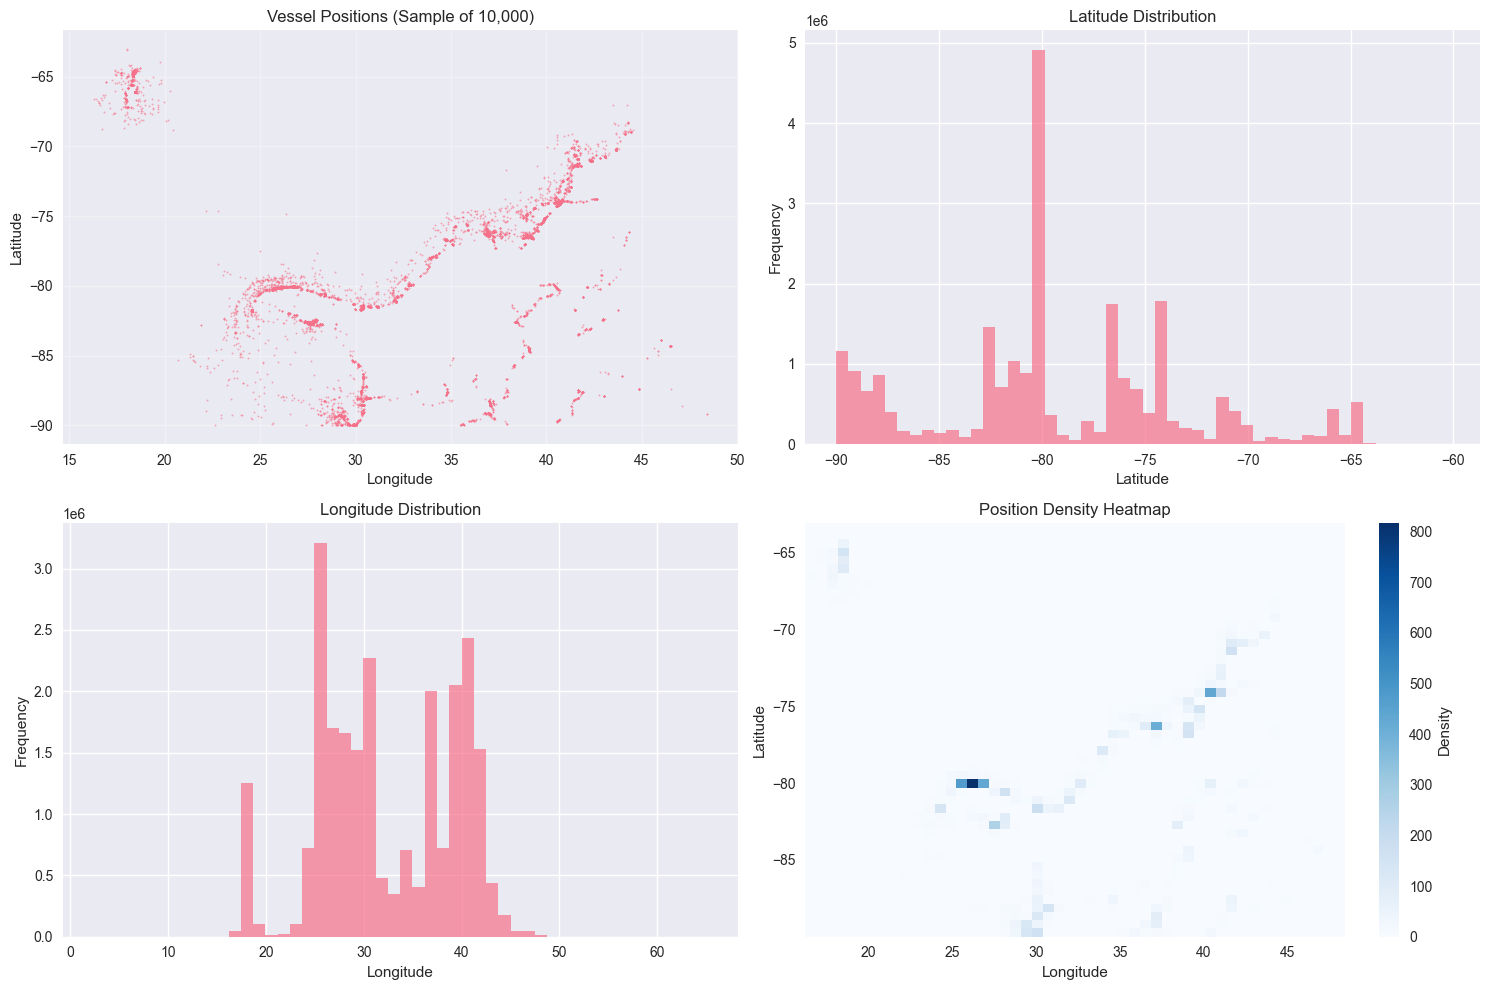


🗺️ Creating interactive density heatmap...
Interactive map saved to: ../data/ais_density_map.html
Open this file in a web browser to view the interactive map


In [11]:
## 6. Geographic Analysis

print("🌍 Geographic Distribution Analysis")
print("=" * 40)

# Find coordinate columns
lat_cols = [col for col in analysis_df.columns if any(word in col.upper() for word in ['LAT', 'LATITUDE'])]
lon_cols = [col for col in analysis_df.columns if any(word in col.upper() for word in ['LON', 'LONGITUDE', 'LOT'])]

if lat_cols and lon_cols:
    lat_col = lat_cols[0]
    lon_col = lon_cols[0]
    print(f"Using coordinate columns: {lat_col}, {lon_col}")
    
    # Filter valid coordinates
    valid_coords = (
        (analysis_df[lat_col] >= -90) & (analysis_df[lat_col] <= 90) &
        (analysis_df[lon_col] >= -180) & (analysis_df[lon_col] <= 180) &
        analysis_df[lat_col].notna() & analysis_df[lon_col].notna()
    )
    
    geo_df = analysis_df[valid_coords].copy()
    print(f"\nValid coordinates: {len(geo_df):,} / {len(analysis_df):,} ({len(geo_df)/len(analysis_df)*100:.1f}%)")
    
    if len(geo_df) > 0:
        # Geographic bounds and center
        print(f"\n🗺️ Geographic Coverage:")
        print(f"  Latitude range: [{geo_df[lat_col].min():.4f}, {geo_df[lat_col].max():.4f}]")
        print(f"  Longitude range: [{geo_df[lon_col].min():.4f}, {geo_df[lon_col].max():.4f}]")
        print(f"  Center point: ({geo_df[lat_col].mean():.4f}, {geo_df[lon_col].mean():.4f})")
        
        # Geographic distribution visualization
        plt.figure(figsize=(15, 10))
        
        # Scatter plot of all positions
        plt.subplot(2, 2, 1)
        sample_geo = geo_df.sample(min(10000, len(geo_df)))  # Sample for performance
        plt.scatter(sample_geo[lon_col], sample_geo[lat_col], alpha=0.5, s=1)
        plt.title(f'Vessel Positions (Sample of {len(sample_geo):,})')
        plt.xlabel('Longitude')
        plt.ylabel('Latitude')
        plt.grid(True, alpha=0.3)
        
        # Latitude distribution
        plt.subplot(2, 2, 2)
        geo_df[lat_col].hist(bins=50, alpha=0.7)
        plt.title('Latitude Distribution')
        plt.xlabel('Latitude')
        plt.ylabel('Frequency')
        
        # Longitude distribution
        plt.subplot(2, 2, 3)
        geo_df[lon_col].hist(bins=50, alpha=0.7)
        plt.title('Longitude Distribution')
        plt.xlabel('Longitude')
        plt.ylabel('Frequency')
        
        # 2D density plot
        plt.subplot(2, 2, 4)
        plt.hist2d(sample_geo[lon_col], sample_geo[lat_col], bins=50, cmap='Blues')
        plt.colorbar(label='Density')
        plt.title('Position Density Heatmap')
        plt.xlabel('Longitude')
        plt.ylabel('Latitude')
        
        plt.tight_layout()
        plt.show()
        
        # Create density heatmap using Folium
        try:
            print("\n🗺️ Creating interactive density heatmap...")
            density_map = visualizer.create_density_heatmap(geo_df, lat_col, lon_col)
            
            # Save the map
            map_path = '../data/ais_density_map.html'
            density_map.save(map_path)
            print(f"Interactive map saved to: {map_path}")
            print("Open this file in a web browser to view the interactive map")
            
        except Exception as e:
            print(f"⚠️ Error creating density heatmap: {e}")
    
else:
    print("⚠️ No valid coordinate columns found for geographic analysis")


⚡ Speed and Movement Analysis
Using speed column: SOG

📊 Speed Statistics:
  Records with speed data: 53,787,420
  Speed range: [0.00, 99.80]
  Mean speed: 1.86 knots
  Median speed: 0.00 knots
  Standard deviation: 4.12 knots
  Reasonable speeds (0-50 knots): 53,786,820 (100.0%)

⚡ Speed Categories:
  Anchored (0-1): 41,350,254 (76.9%)
  Slow (5-10): 5,031,846 (9.4%)
  Very Slow (1-5): 4,033,497 (7.5%)
  Medium (10-15): 2,335,963 (4.3%)
  Fast (15-25): 900,971 (1.7%)
  Very Fast (25-50): 134,289 (0.2%)


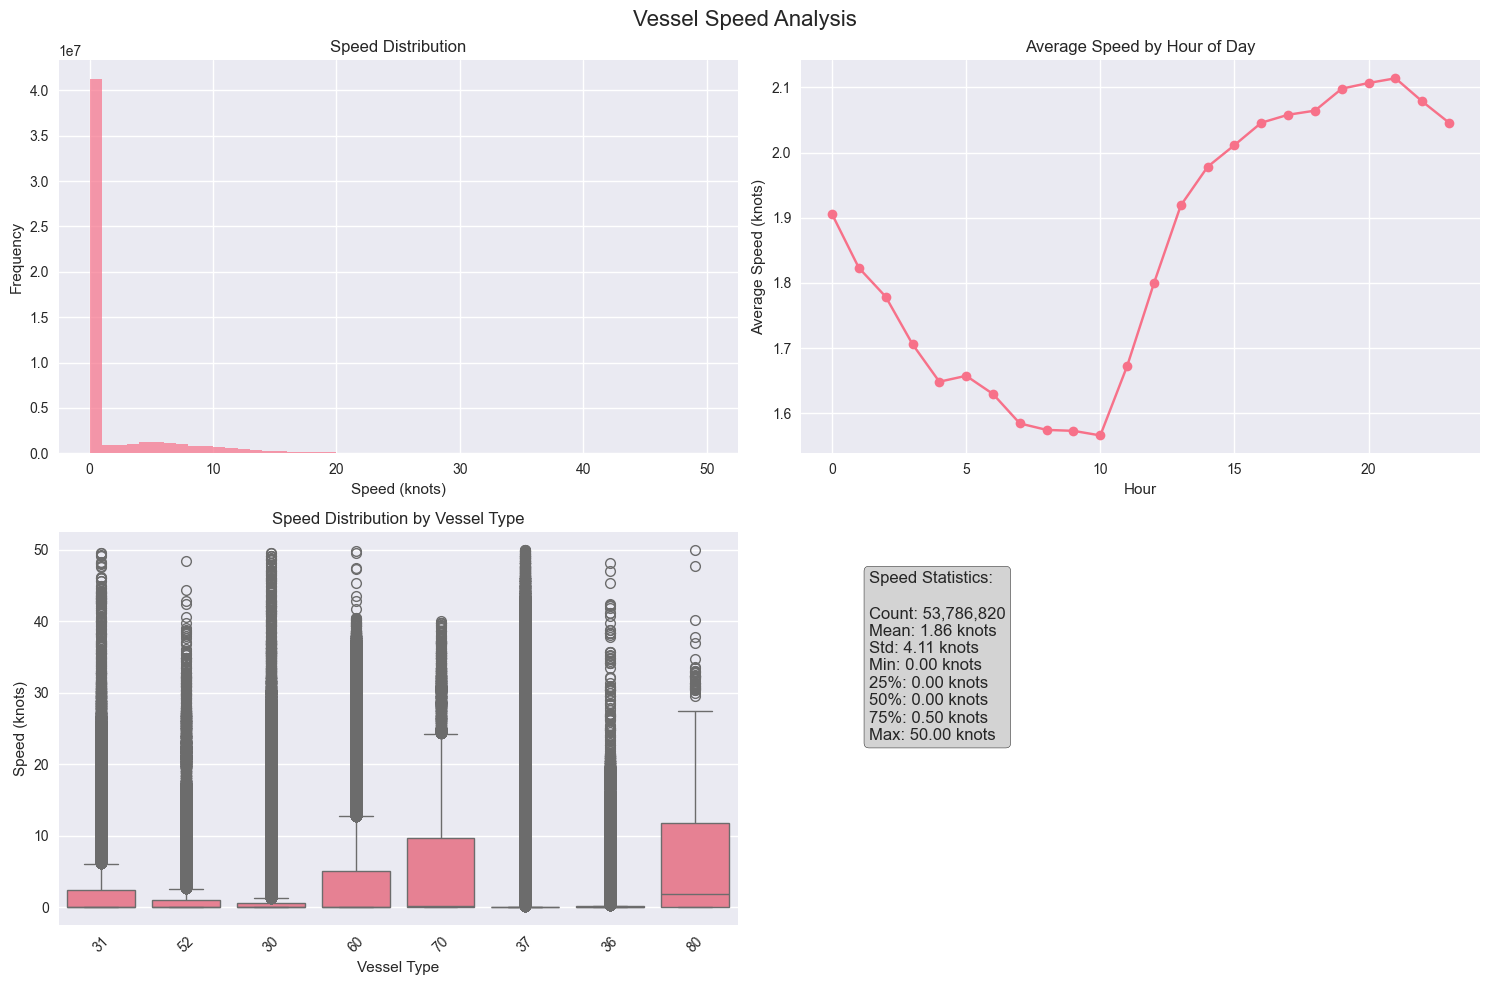


🧭 Course Analysis (using COG):
  Records with course data: 44,555,824
  Valid courses (0-360°): 44,555,824 (100.0%)


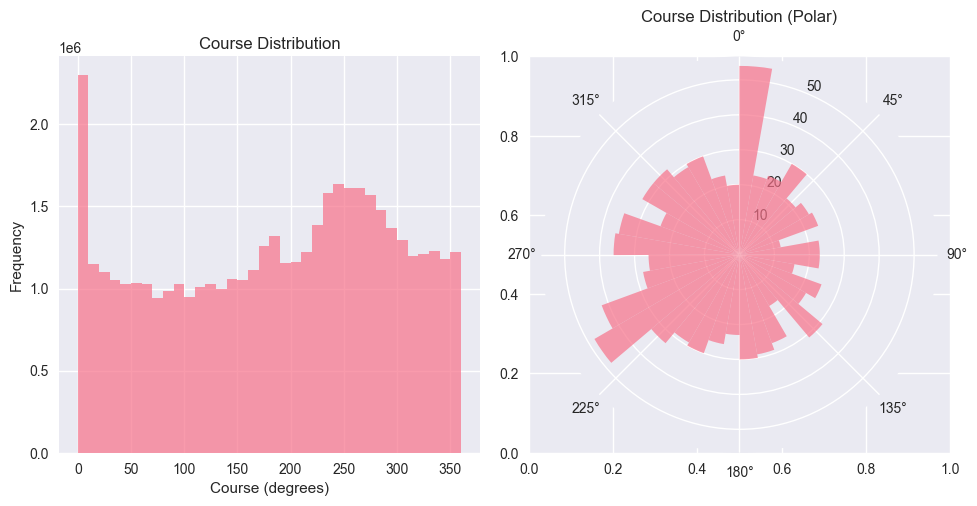

In [12]:
## 7. Speed and Movement Analysis

print("⚡ Speed and Movement Analysis")
print("=" * 35)

# Find speed columns (SOG = Speed Over Ground, COG = Course Over Ground)
speed_cols = [col for col in analysis_df.columns if any(word in col.upper() for word in ['SOG', 'SPEED'])]
course_cols = [col for col in analysis_df.columns if any(word in col.upper() for word in ['COG', 'COURSE', 'HEADING'])]

if speed_cols:
    speed_col = speed_cols[0]
    print(f"Using speed column: {speed_col}")
    
    # Basic speed statistics
    speed_data = analysis_df[speed_col].dropna()
    print(f"\n📊 Speed Statistics:")
    print(f"  Records with speed data: {len(speed_data):,}")
    print(f"  Speed range: [{speed_data.min():.2f}, {speed_data.max():.2f}]")
    print(f"  Mean speed: {speed_data.mean():.2f} knots")
    print(f"  Median speed: {speed_data.median():.2f} knots")
    print(f"  Standard deviation: {speed_data.std():.2f} knots")
    
    # Filter reasonable speeds for analysis (0-50 knots is typical for most vessels)
    reasonable_speeds = speed_data[(speed_data >= 0) & (speed_data <= 50)]
    print(f"  Reasonable speeds (0-50 knots): {len(reasonable_speeds):,} ({len(reasonable_speeds)/len(speed_data)*100:.1f}%)")
    
    # Speed categories
    speed_categories = pd.cut(reasonable_speeds, 
                            bins=[0, 1, 5, 10, 15, 25, 50], 
                            labels=['Anchored (0-1)', 'Very Slow (1-5)', 'Slow (5-10)', 
                                   'Medium (10-15)', 'Fast (15-25)', 'Very Fast (25-50)'],
                            include_lowest=True)
    
    print(f"\n⚡ Speed Categories:")
    for category, count in speed_categories.value_counts().items():
        pct = count / len(reasonable_speeds) * 100
        print(f"  {category}: {count:,} ({pct:.1f}%)")
    
    # Create speed analysis visualization
    try:
        fig_speed = visualizer.plot_vessel_speed_analysis(analysis_df, speed_col)
        plt.show()
    except Exception as e:
        print(f"⚠️ Error creating speed visualization: {e}")
        
        # Manual speed visualization
        plt.figure(figsize=(12, 8))
        
        plt.subplot(2, 2, 1)
        reasonable_speeds.hist(bins=50, alpha=0.7)
        plt.title('Speed Distribution (0-50 knots)')
        plt.xlabel('Speed (knots)')
        plt.ylabel('Frequency')
        
        plt.subplot(2, 2, 2)
        speed_categories.value_counts().plot(kind='bar')
        plt.title('Vessel Speed Categories')
        plt.xlabel('Speed Category')
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        
        # If timestamp available, show speed over time
        if timestamp_cols and len(timestamp_cols) > 0:
            plt.subplot(2, 2, 3)
            speed_with_time = analysis_df[analysis_df[speed_col].between(0, 50)].copy()
            speed_with_time['hour'] = pd.to_datetime(speed_with_time[timestamp_cols[0]]).dt.hour
            hourly_avg_speed = speed_with_time.groupby('hour')[speed_col].mean()
            hourly_avg_speed.plot(kind='line', marker='o')
            plt.title('Average Speed by Hour')
            plt.xlabel('Hour of Day')
            plt.ylabel('Average Speed (knots)')
        
        plt.subplot(2, 2, 4)
        # Speed percentiles
        percentiles = [10, 25, 50, 75, 90, 95, 99]
        speed_percentiles = [reasonable_speeds.quantile(p/100) for p in percentiles]
        plt.bar(range(len(percentiles)), speed_percentiles)
        plt.title('Speed Percentiles')
        plt.xlabel('Percentile')
        plt.ylabel('Speed (knots)')
        plt.xticks(range(len(percentiles)), [f'{p}th' for p in percentiles])
        
        plt.tight_layout()
        plt.show()

else:
    print("⚠️ No speed column found for movement analysis")

# Course analysis if available
if course_cols:
    course_col = course_cols[0]
    print(f"\n🧭 Course Analysis (using {course_col}):")
    
    course_data = analysis_df[course_col].dropna()
    print(f"  Records with course data: {len(course_data):,}")
    
    # Course should be 0-360 degrees
    valid_courses = course_data[(course_data >= 0) & (course_data <= 360)]
    print(f"  Valid courses (0-360°): {len(valid_courses):,} ({len(valid_courses)/len(course_data)*100:.1f}%)")
    
    if len(valid_courses) > 100:
        # Course distribution (compass directions)
        plt.figure(figsize=(10, 5))
        
        plt.subplot(1, 2, 1)
        valid_courses.hist(bins=36, alpha=0.7)  # 36 bins = 10° each
        plt.title('Course Distribution')
        plt.xlabel('Course (degrees)')
        plt.ylabel('Frequency')
        
        plt.subplot(1, 2, 2)
        # Polar plot of courses
        ax = plt.subplot(1, 2, 2, projection='polar')
        theta = np.radians(valid_courses.sample(min(1000, len(valid_courses))))  # Sample for performance
        ax.hist(theta, bins=36, alpha=0.7)
        ax.set_title('Course Distribution (Polar)')
        ax.set_theta_zero_location('N')
        ax.set_theta_direction(-1)
        
        plt.tight_layout()
        plt.show()


🎮 Interactive Visualizations
🗺️ Creating vessel trajectory plot...



📊 Creating interactive dashboard...
⚠️ Error creating interactive visualizations: 
The 'specs' argument to make_subplots must be a 2D list of dictionaries with dimensions (2 x 2).
    Received value of type <class 'list'>: [['mapbox', 'scatter'], ['bar', 'histogram']]
This might be due to missing coordinate columns or large dataset size

🚢 Vessel Type Analysis (using VesselType):
  Unique vessel types: 79
  Top 10 vessel types:
     1. 37: 11,317,414 (21.0%)
     2. 31: 9,721,263 (18.0%)
     3. 52: 8,973,164 (16.6%)
     4. 70: 3,612,446 (6.7%)
     5. 36: 3,491,519 (6.5%)
     6. 30: 3,379,390 (6.3%)
     7. 60: 3,220,050 (6.0%)
     8. 80: 1,607,588 (3.0%)
     9. 57: 1,121,620 (2.1%)
    10. 90: 1,002,465 (1.9%)


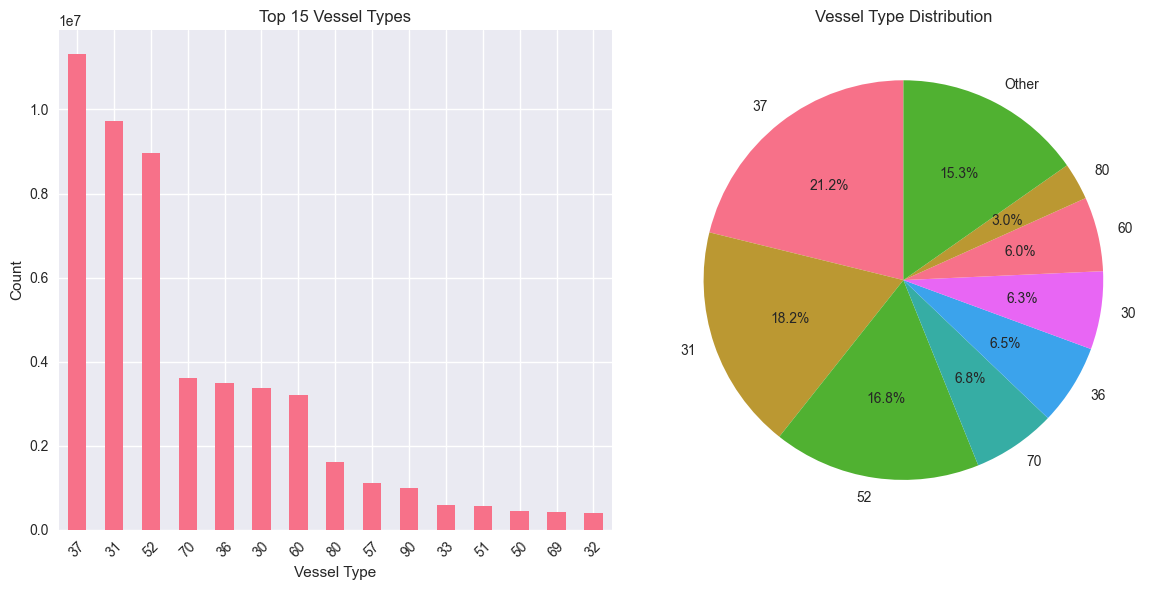

In [13]:
## 8. Interactive Visualizations

print("🎮 Interactive Visualizations")
print("=" * 35)

try:
    # Vessel trajectories for top vessels
    if 'vessel_col' in locals() and lat_cols and lon_cols:
        print("🗺️ Creating vessel trajectory plot...")
        fig_trajectories = visualizer.plot_vessel_trajectories(
            analysis_df, vessel_col, lat_col, lon_col, 
            timestamp_col if 'timestamp_col' in locals() else None
        )
        fig_trajectories.show()
    
    # Interactive dashboard
    print("\n📊 Creating interactive dashboard...")
    dashboard_params = {}
    if lat_cols and lon_cols:
        dashboard_params['lat_col'] = lat_col
        dashboard_params['lon_col'] = lon_col
    if 'vessel_col' in locals():
        dashboard_params['vessel_col'] = vessel_col
    if 'timestamp_col' in locals():
        dashboard_params['timestamp_col'] = timestamp_col
    
    fig_dashboard = visualizer.create_interactive_dashboard(analysis_df, **dashboard_params)
    fig_dashboard.show()
    
except Exception as e:
    print(f"⚠️ Error creating interactive visualizations: {e}")
    print("This might be due to missing coordinate columns or large dataset size")

# Vessel type analysis (if available)
vessel_type_cols = [col for col in analysis_df.columns if any(word in col.upper() for word in ['TYPE', 'VESSEL_TYPE', 'SHIPTYPE'])]
if vessel_type_cols:
    type_col = vessel_type_cols[0]
    print(f"\n🚢 Vessel Type Analysis (using {type_col}):")
    
    type_counts = analysis_df[type_col].value_counts()
    print(f"  Unique vessel types: {len(type_counts)}")
    print(f"  Top 10 vessel types:")
    for i, (vtype, count) in enumerate(type_counts.head(10).items(), 1):
        pct = count / len(analysis_df) * 100
        print(f"    {i:2d}. {vtype}: {count:,} ({pct:.1f}%)")
    
    # Visualize vessel types
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    type_counts.head(15).plot(kind='bar')
    plt.title('Top 15 Vessel Types')
    plt.xlabel('Vessel Type')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    
    plt.subplot(1, 2, 2)
    # Pie chart for top types
    top_types = type_counts.head(8)
    other_count = type_counts.iloc[8:].sum()
    if other_count > 0:
        pie_data = pd.concat([top_types, pd.Series({'Other': other_count})])
    else:
        pie_data = top_types
    
    plt.pie(pie_data.values, labels=pie_data.index, autopct='%1.1f%%', startangle=90)
    plt.title('Vessel Type Distribution')
    
    plt.tight_layout()
    plt.show()


In [14]:
## 9. Comprehensive Summary Report

print("📋 Comprehensive AIS Data Summary Report")
print("=" * 45)

# Generate detailed summary report
try:
    report_params = {}
    if 'vessel_col' in locals():
        report_params['vessel_col'] = vessel_col
    if lat_cols and lon_cols:
        report_params['lat_col'] = lat_col
        report_params['lon_col'] = lon_col
    if 'timestamp_col' in locals():
        report_params['timestamp_col'] = timestamp_col
    
    summary_report = create_summary_report(analysis_df, **report_params)
    
    print("=" * 60)
    print("📊 DATASET OVERVIEW")
    print("=" * 60)
    overview = summary_report['dataset_overview']
    print(f"Total Records: {overview['total_records']:,}")
    print(f"Memory Usage: {overview['memory_usage_mb']:.2f} MB")
    print(f"Number of Columns: {len(overview['columns'])}")
    print(f"Columns: {', '.join(overview['columns'])}")
    
    if overview['date_range']:
        print(f"Date Range: {overview['date_range']['start']} to {overview['date_range']['end']}")
    
    if overview['geographic_bounds']:
        bounds = overview['geographic_bounds']
        print(f"Geographic Center: ({bounds['center_lat']:.4f}, {bounds['center_lon']:.4f})")
        print(f"Latitude Range: [{bounds['lat_min']:.4f}, {bounds['lat_max']:.4f}]")
        print(f"Longitude Range: [{bounds['lon_min']:.4f}, {bounds['lon_max']:.4f}]")
    
    print("\n" + "=" * 60)
    print("🔍 DATA QUALITY")
    print("=" * 60)
    quality = summary_report['data_quality']
    print(f"Duplicate Records: {quality['duplicate_records']:,}")
    print(f"Valid Coordinates: {quality['valid_coordinates_pct']:.1f}%")
    
    if quality['missing_values']:
        print("\nMissing Values:")
        for col, missing in quality['missing_values'].items():
            if missing > 0:
                pct = missing / overview['total_records'] * 100
                print(f"  {col}: {missing:,} ({pct:.1f}%)")
    
    print("\n" + "=" * 60)
    print("🚢 VESSEL STATISTICS")
    print("=" * 60)
    vessel_stats = summary_report['vessel_statistics']
    if vessel_stats['unique_vessels'] > 0:
        print(f"Unique Vessels: {vessel_stats['unique_vessels']:,}")
        print(f"Average Records per Vessel: {vessel_stats['avg_records_per_vessel']:.1f}")
        
        print("\nMost Active Vessels:")
        for i, (vessel, count) in enumerate(list(vessel_stats['most_active_vessels'].items())[:5], 1):
            pct = count / overview['total_records'] * 100
            print(f"  {i}. Vessel {vessel}: {count:,} records ({pct:.2f}%)")
    
    print("\n" + "=" * 60)
    print("⏰ TEMPORAL PATTERNS")
    print("=" * 60)
    temporal = summary_report['temporal_patterns']
    
    if temporal['records_per_day']:
        daily_data = temporal['records_per_day']
        print(f"Days with Data: {len(daily_data)}")
        print(f"Average Records per Day: {sum(daily_data.values()) / len(daily_data):,.0f}")
        print(f"Busiest Day: {max(daily_data.items(), key=lambda x: x[1])}")
        print(f"Quietest Day: {min(daily_data.items(), key=lambda x: x[1])}")
    
    if temporal['peak_hours']:
        peak_hour = max(temporal['peak_hours'].items(), key=lambda x: x[1])
        quiet_hour = min(temporal['peak_hours'].items(), key=lambda x: x[1])
        print(f"Peak Hour: {peak_hour[0]}:00 ({peak_hour[1]:,} records)")
        print(f"Quietest Hour: {quiet_hour[0]}:00 ({quiet_hour[1]:,} records)")
    
except Exception as e:
    print(f"⚠️ Error generating summary report: {e}")

print("\n" + "=" * 60)
print("💡 KEY INSIGHTS AND RECOMMENDATIONS")
print("=" * 60)

insights = []

# Data volume insights
if len(analysis_df) > 1000000:
    insights.append("🔍 Large Dataset: Consider using data sampling or chunking for memory-intensive operations")
elif len(analysis_df) < 10000:
    insights.append("📊 Small Dataset: Full dataset analysis is feasible for all operations")

# Vessel activity insights
if 'vessel_col' in locals():
    vessel_activity = analysis_df[vessel_col].value_counts()
    single_record_vessels = (vessel_activity == 1).sum()
    if single_record_vessels > total_vessels * 0.5:
        insights.append("🚢 High number of vessels with single records - potential data quality issue or transient vessels")

# Geographic insights
if lat_cols and lon_cols:
    lat_range = geo_df[lat_col].max() - geo_df[lat_col].min()
    lon_range = geo_df[lon_col].max() - geo_df[lon_col].min()
    if lat_range > 10 or lon_range > 10:
        insights.append("🌍 Wide geographic coverage detected - consider regional analysis")
    else:
        insights.append("📍 Localized geographic area - good for detailed regional analysis")

# Speed insights
if speed_cols:
    stationary_vessels = (analysis_df[speed_col] < 1).sum()
    if stationary_vessels > len(analysis_df) * 0.3:
        insights.append("⚓ High percentage of stationary/anchored vessels detected")

# Temporal insights
if 'timestamp_col' in locals():
    time_span = analysis_df[timestamp_col].max() - analysis_df[timestamp_col].min()
    if time_span.days > 7:
        insights.append("📅 Multi-day dataset suitable for temporal trend analysis")

if insights:
    for insight in insights:
        print(insight)
else:
    print("✅ Analysis completed successfully - review the visualizations above for detailed insights")

print("\n🎯 NEXT STEPS:")
print("1. Focus on specific vessel types or geographic regions of interest")
print("2. Investigate anomalous speed or course patterns")
print("3. Perform trajectory analysis for high-activity vessels")
print("4. Consider machine learning approaches for pattern recognition")
print("5. Cross-reference with weather data or port information")

print("\n" + "=" * 60)
print("✅ ANALYSIS COMPLETE")
print("=" * 60)


📋 Comprehensive AIS Data Summary Report
📊 DATASET OVERVIEW
Total Records: 53,910,197
Memory Usage: 25628.48 MB
Number of Columns: 19
Columns: MMSI, BaseDateTime, LAT, LON, SOG, COG, Heading, VesselName, IMO, CallSign, VesselType, Status, Length, Width, Draft, Cargo, TransceiverClass, source_file, day_of_week
Date Range: 2025-03-01 00:00:00 to 2025-03-07 23:59:59
Geographic Center: (-79.3076, 32.3689)
Latitude Range: [-90.0000, -60.1985]
Longitude Range: [2.3767, 65.0740]

🔍 DATA QUALITY
Duplicate Records: 13,585
Valid Coordinates: 44.6%

Missing Values:
  SOG: 122,777 (0.2%)
  COG: 9,354,373 (17.4%)
  Heading: 26,942,703 (50.0%)
  VesselName: 60,229 (0.1%)
  IMO: 32,620,945 (60.5%)
  CallSign: 6,331,457 (11.7%)
  VesselType: 424,042 (0.8%)
  Status: 18,533,062 (34.4%)
  Length: 1,072,646 (2.0%)
  Width: 1,812,121 (3.4%)
  Draft: 23,441,183 (43.5%)
  Cargo: 17,320,894 (32.1%)

🚢 VESSEL STATISTICS
Unique Vessels: 26,121
Average Records per Vessel: 2063.9

Most Active Vessels:
  1. Vessel

In [ ]:
# 📝 How to Use This Notebook

print("🚀 AIS Data Exploration Notebook - Usage Instructions")
print("=" * 55)
print()
print("This notebook provides comprehensive exploratory analysis of your AIS maritime data.")
print("Follow these steps to get the most out of your analysis:")
print()
print("1. ✅ PREREQUISITES:")
print("   • Ensure parquet files are in '../data/march_2025_files/'")
print("   • Install required packages: pip install -r ../../requirements.txt")
print("   • Run cells sequentially for best results")
print()
print("2. 🔧 CUSTOMIZATION:")
print("   • Modify 'sample_files = parquet_files[:7]' to analyze more/fewer days")
print("   • Adjust visualization parameters in AISVisualizer class")
print("   • Add custom analysis sections as needed")
print()
print("3. 📊 KEY OUTPUTS:")
print("   • Interactive HTML maps saved to '../data/'")
print("   • Statistical summaries and visualizations")
print("   • Data quality assessments")
print("   • Vessel activity patterns")
print()
print("4. 🎯 NEXT STEPS AFTER RUNNING:")
print("   • Review the summary report at the end")
print("   • Investigate anomalies highlighted in the analysis")
print("   • Consider focusing on specific geographic regions or vessel types")
print("   • Use insights for fraud detection or route optimization")
print()
print("💡 TIP: This notebook is designed to handle large datasets efficiently")
print("    by sampling data for visualizations while preserving analytical accuracy.")
print()
print("🆘 If you encounter memory issues, reduce the number of files loaded")
print("    in Section 3 or increase sampling in the visualizer settings.")
print()
print("Happy analyzing! 🔍⚓")

# Display final summary
if 'analysis_df' in locals():
    print(f"\n📈 Current Analysis Dataset:")
    print(f"   Records: {len(analysis_df):,}")
    print(f"   Columns: {len(analysis_df.columns)}")
    print(f"   Memory: {analysis_df.memory_usage(deep=True).sum() / 1024 / 1024:.1f} MB")
    if 'source_file' in analysis_df.columns:
        print(f"   Files: {analysis_df['source_file'].nunique()}")
        print(f"   Date range: {analysis_df['source_file'].min()} to {analysis_df['source_file'].max()}")
